# Phase 6: Is economic growth translating into development?

**The question:** between 2000 and 2025, did GDP growth in Nigeria, Kenya, Ghana, Rwanda and South Africa come with
less poverty, more jobs and wider mobile access?

**How this notebook is organised.** Each section asks one question, then:
1. a chart (or table) that answers it, and
2. **What this shows**: the answer in plain words, plus any caveat.

**Rules we follow:**
- **Read only from the marts** (`fct_growth_vs_development`, `fct_poverty_survey_spans`). Never raw tables: the marts are tested, documented and agreed, so every number here traces back through dbt.
- **"Moved together", never "caused".** Five countries and 21 survey pairs can show patterns, not prove causes.
- **No forward-filling poverty.** It is measured only in survey years, so we compare survey to survey.

Run top to bottom with **Shift + Enter**. Kernel: **Python (econdev)**.

## 0. Setup and loading the marts

Project id comes from `config/indicators.yml`, the same file the pipeline uses. Colours are fixed **per country**
(Nigeria is always blue, Kenya always orange...) so you never have to re-learn the legend between charts.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pandas_gbq
import yaml

config = yaml.safe_load(Path("../config/indicators.yml").read_text())
PROJECT = config["bigquery"]["project"]
MARTS = f"{PROJECT}.dbt_dev"


def read_mart(name):
    return pandas_gbq.read_gbq(f"select * from `{MARTS}.{name}`", project_id=PROJECT, progress_bar_type=None)


country_year = read_mart("fct_growth_vs_development").sort_values(["country_iso3", "year"])
spans = read_mart("fct_poverty_survey_spans").sort_values(["country_iso3", "start_year"])

# One colour and one marker per country, used in every chart
COUNTRIES = ["NGA", "KEN", "GHA", "RWA", "ZAF"]
NAMES = country_year.drop_duplicates("country_iso3").set_index("country_iso3")["country_name"].to_dict()
COLORS = dict(zip(COUNTRIES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
MARKERS = dict(zip(COUNTRIES, ["o", "s", "^", "D", "v"]))
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.figsize": (10, 5), "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "lines.linewidth": 2, "legend.frameon": False,
})


def label_line_ends(ax, df, value_col, fmt="{:.0f}"):
    """Write each country's name at the end of its line, so colour is never the only clue."""
    ends = df.dropna(subset=[value_col]).groupby("country_iso3").tail(1).sort_values(value_col)
    min_gap = 0.045 * (df[value_col].max() - df[value_col].min())  # push labels apart if lines end close together
    label_y = []
    for value in ends[value_col]:
        label_y.append(max(value, label_y[-1] + min_gap) if label_y else value)
    for (_, row), y in zip(ends.iterrows(), label_y):
        ax.annotate(f"{NAMES[row.country_iso3]} {fmt.format(row[value_col])}", (row.year, row[value_col]),
                    xytext=(row.year + 0.4, y), textcoords="data", va="center", fontsize=9, color=INK)


print(f"country_year: {len(country_year)} rows, {country_year.year.min()}-{country_year.year.max()}")
print(f"spans:        {len(spans)} rows")

country_year: 130 rows, 2000-2025
spans:        21 rows


### Sanity check: is the data what we think it is?

Before any chart, confirm the **grain** (one row per country-year, one row per survey pair) and the row counts dbt reported.
If these fail, stop: every chart below would be wrong.

In [2]:
assert len(country_year) == 130 and not country_year.duplicated(["country_iso3", "year"]).any()
assert len(spans) == 21 and not spans.duplicated(["country_iso3", "start_year"]).any()

coverage = country_year.groupby("country_iso3")[["gdp_growth_pct", "poverty_pct", "unemployment_pct", "mobile_per_100"]].count()
coverage.index = coverage.index.map(NAMES)
coverage.columns = ["GDP growth", "Poverty (survey years)", "Unemployment", "Mobile"]
coverage

,GDP growth,Poverty (survey years),Unemployment,Mobile
country_iso3,,,,
Ghana,26,3,26,25
Kenya,26,5,26,25
Nigeria,26,6,26,25
Rwanda,26,6,26,25
South Africa,26,6,26,25


**What this shows:** both marts have the expected grain. Every country has 26 years of GDP growth and unemployment,
but **only 3–6 poverty surveys**, which is why poverty gets its own survey-to-survey mart. Mobile has 25 years: the
World Bank hasn't published 2025 yet.

## 1. How fast has each economy grown?

**Sub-question 1a: on average, over 2000–2025?** We compare two periods, because the story changes after 2015.

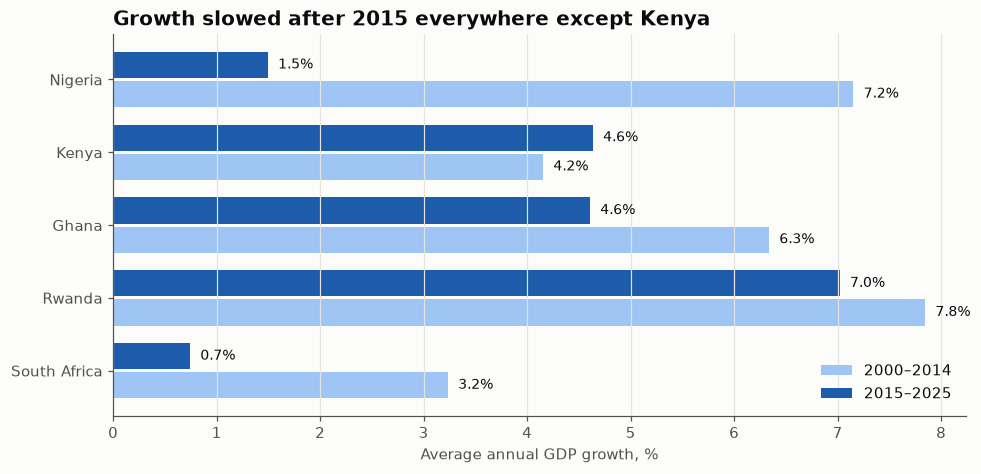

In [3]:
period = pd.cut(country_year.year, [1999, 2014, 2025], labels=["2000–2014", "2015–2025"])
avg_growth = (country_year.groupby(["country_iso3", period], observed=True).gdp_growth_pct.mean()
              .unstack().reindex(COUNTRIES))

fig, ax = plt.subplots(figsize=(10, 4.5))
y = range(len(COUNTRIES))
ax.barh([i + 0.2 for i in y], avg_growth["2000–2014"], height=0.36, color="#9ec5f4", label="2000–2014")
ax.barh([i - 0.2 for i in y], avg_growth["2015–2025"], height=0.36, color="#1c5cab", label="2015–2025")
for i, c in enumerate(COUNTRIES):
    for offset, col in [(0.2, "2000–2014"), (-0.2, "2015–2025")]:
        ax.text(avg_growth.loc[c, col] + 0.1, i + offset, f"{avg_growth.loc[c, col]:.1f}%", va="center", fontsize=9)
ax.set_yticks(list(y), [NAMES[c] for c in COUNTRIES])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("Average annual GDP growth, %")
ax.set_title("Growth slowed after 2015 everywhere except Kenya")
ax.legend(loc="lower right")
plt.show()

**What this shows:**
- **Rwanda grew fastest in both periods** (7.8% then 7.0% a year), the most consistent of the five.
- **Nigeria had the biggest slowdown**: from 7.2% to 1.5% a year. With population growing ~2.5% a year, 1.5% growth means the average Nigerian got *poorer*.
- **South Africa grew slowest throughout**, falling to 0.7% a year after 2015.
- **Kenya is the only country that held steady** (4.2% → 4.6%).

**Sub-question 1b: was growth steady, or did it swing?** Yearly growth is noisy, so we plot the **5-year rolling average** from the mart.
It starts in 2004, the first year with 5 years of data behind it.

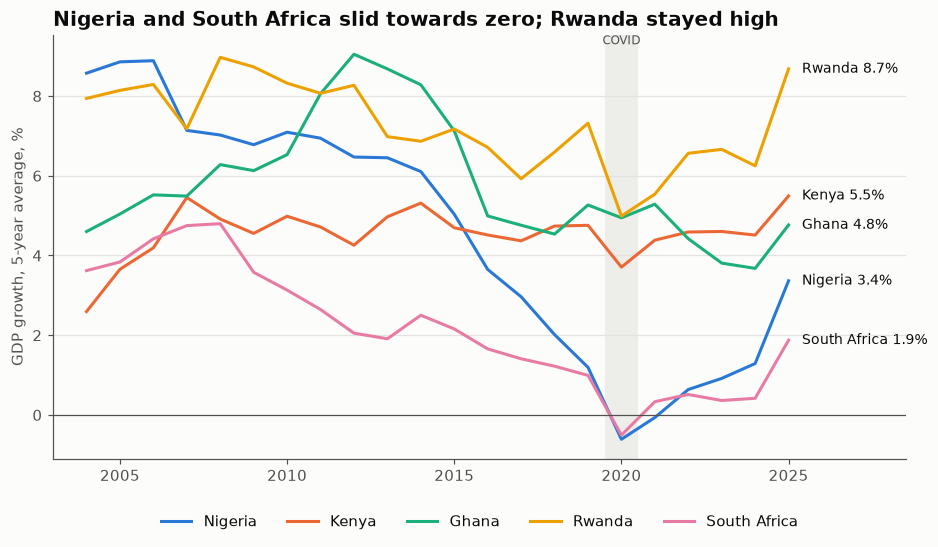

In [4]:
fig, ax = plt.subplots()
for c in COUNTRIES:
    d = country_year[country_year.country_iso3 == c]
    ax.plot(d.year, d.gdp_growth_5yr_avg, color=COLORS[c], label=NAMES[c])
label_line_ends(ax, country_year, "gdp_growth_5yr_avg", fmt="{:.1f}%")
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.axvspan(2019.5, 2020.5, color=GRID, alpha=0.6, linewidth=0)
ax.text(2020, ax.get_ylim()[1], "COVID", ha="center", va="top", fontsize=8, color=MUTED)
ax.set_xlim(2003, 2028.5)
ax.set_ylabel("GDP growth, 5-year average, %")
ax.set_title("Nigeria and South Africa slid towards zero; Rwanda stayed high")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

**What this shows:** the gap between countries **widened over time**. Nigeria's average fell from about 9% in 2006
to just below zero in 2020 (the 2016 oil-price recession, then COVID). South Africa drifted from ~4% to near zero.
Rwanda and Kenya stayed steady. 2020 was the only year all five were hit at once.

**Reading tip:** the jump in 2025 (Nigeria 1.3% → 3.4%) is mostly a rolling-average effect, not a boom. 2020 has just dropped
out of the 5-year window, so the average rises even though 2025 itself was an ordinary year (4.0%).

**Answer to Q1:** growth was strong in the 2000s, but since 2015 only **Rwanda, Kenya and Ghana** have kept growing fast.
Nigeria and South Africa have barely grown.

## 2. Did poverty fall?

Poverty = % of people living on less than **$3.00 a day** (2021 prices). We plot **only real survey years** (dots).
The dashed lines just connect surveys: we have no data between them, so we don't pretend to.

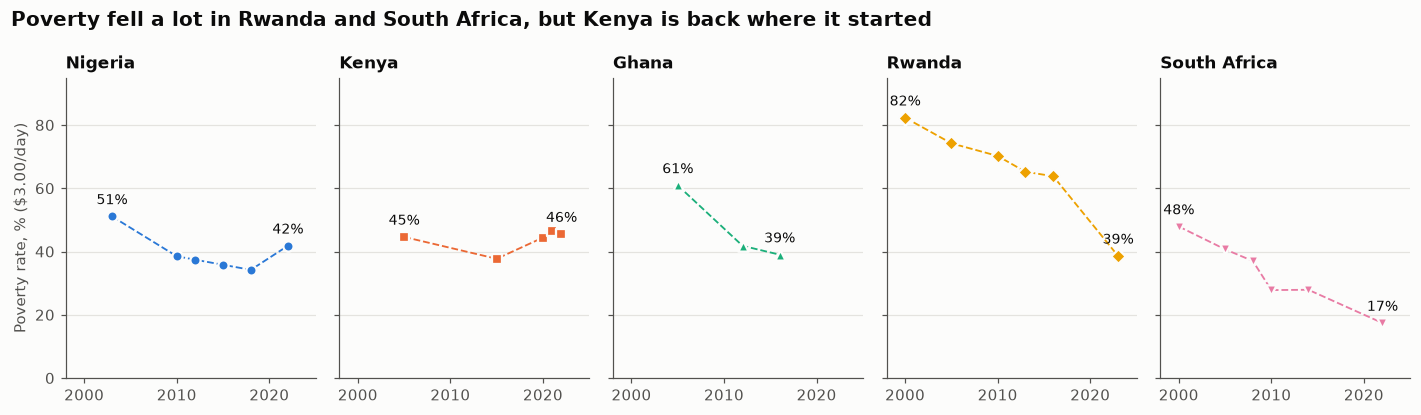

,first_year,first_pct,last_year,last_pct,change_pp
country_iso3,,,,,
Nigeria,2003,51.1,2022,41.8,-9.3
Kenya,2005,44.6,2022,45.5,0.9
Ghana,2005,60.9,2016,39.0,-21.9
Rwanda,2000,82.3,2023,38.6,-43.7
South Africa,2000,47.9,2022,17.4,-30.5


In [5]:
fig, axes = plt.subplots(1, 5, figsize=(13, 3.8), sharey=True)
surveys = country_year[country_year.is_poverty_survey_year]
for ax, c in zip(axes, COUNTRIES):
    d = surveys[surveys.country_iso3 == c]
    ax.plot(d.year, d.poverty_pct, color=COLORS[c], linestyle="--", linewidth=1.2)
    ax.scatter(d.year, d.poverty_pct, color=COLORS[c], marker=MARKERS[c], s=45, zorder=3,
               edgecolor="#fcfcfb", linewidth=1.5)
    first, last = d.iloc[0], d.iloc[-1]
    ax.annotate(f"{first.poverty_pct:.0f}%", (first.year, first.poverty_pct), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9)
    ax.annotate(f"{last.poverty_pct:.0f}%", (last.year, last.poverty_pct), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9)
    ax.set_title(NAMES[c], fontsize=11)
    ax.set_xlim(1998, 2025)
    ax.set_xticks([2000, 2010, 2020])
axes[0].set_ylabel("Poverty rate, % ($3.00/day)")
axes[0].set_ylim(0, 95)
fig.suptitle("Poverty fell a lot in Rwanda and South Africa, but Kenya is back where it started",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
plt.show()

first_last = surveys.groupby("country_iso3").agg(first_year=("year", "first"), first_pct=("poverty_pct", "first"),
                                                last_year=("year", "last"), last_pct=("poverty_pct", "last"))
first_last["change_pp"] = first_last.last_pct - first_last.first_pct
first_last.reindex(COUNTRIES).rename(index=NAMES).round(1)

**What this shows:**
- **Rwanda had the biggest drop:** 82% → 39% (2000 → 2023), most of it between the 2016 and 2023 surveys.
- **South Africa fell** from 48% to 17%, despite having the **slowest growth** of the five. Hold on to that for Q3.
- **Nigeria and Ghana fell, then stalled.** Nigeria's poverty **rose** again between 2018 and 2022 (34% → 42%).
- **Kenya ended about where it started** (45% in 2005, 46% in 2022), after rising after 2015.

**Caveat:** Ghana has only 3 surveys and the latest is 2016, so we don't know what happened after that.

## 3. The core question: between surveys, did faster growth go with faster poverty reduction?

This uses `fct_poverty_survey_spans`: one dot = one pair of back-to-back surveys in one country.

**Why "per year"?** Spans range from 1 to 10 years. A 10-point drop over 10 years is slower than a 5-point drop over 2,
so we divide the poverty change by the span length to compare them fairly.

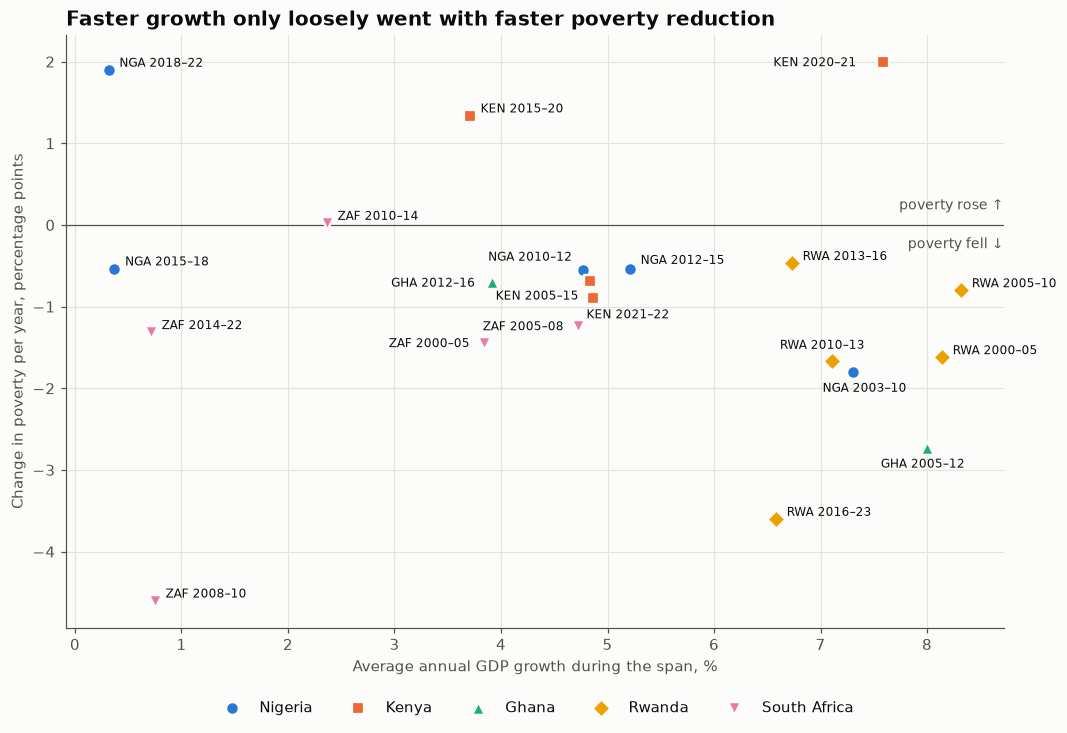

Correlation between growth and yearly poverty change: -0.11  (−1 = perfect 'more growth, less poverty', 0 = no link)
Spans where poverty fell: 17 of 21


In [6]:
spans["poverty_change_pp_per_year"] = spans.poverty_change_pp / spans.span_years

fig, ax = plt.subplots(figsize=(11, 7))
for c in COUNTRIES:
    d = spans[spans.country_iso3 == c]
    ax.scatter(d.avg_gdp_growth_pct, d.poverty_change_pp_per_year, color=COLORS[c], marker=MARKERS[c],
               s=70, label=NAMES[c], edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.grid(axis="x", visible=True)

# Label every span as "country code + years", e.g. "NGA 2018–22".
# Most labels sit just right of the dot; the crowded ones around 5% growth are nudged by hand.
nudge = {("NGA", 2010): (-62, 6), ("KEN", 2005): (-62, -12), ("GHA", 2012): (-66, -3), ("KEN", 2021): (-4, -13),
         ("NGA", 2012): (7, 3), ("ZAF", 2005): (-62, -3), ("ZAF", 2000): (-62, -3), ("KEN", 2020): (-72, -3),
         ("GHA", 2005): (-30, -13), ("RWA", 2010): (-34, 8), ("NGA", 2003): (-20, -13)}
for _, r in spans.iterrows():
    offset = nudge.get((r.country_iso3, r.start_year), (7, 2))
    ax.annotate(f"{r.country_iso3} {r.start_year}–{str(r.end_year)[2:]}", (r.avg_gdp_growth_pct, r.poverty_change_pp_per_year),
                xytext=offset, textcoords="offset points", fontsize=8, color=INK)

ax.text(ax.get_xlim()[1], 0.15, "poverty rose ↑", ha="right", va="bottom", fontsize=9, color=MUTED)
ax.text(ax.get_xlim()[1], -0.15, "poverty fell ↓", ha="right", va="top", fontsize=9, color=MUTED)
ax.set_xlabel("Average annual GDP growth during the span, %")
ax.set_ylabel("Change in poverty per year, percentage points")
ax.set_title("Faster growth only loosely went with faster poverty reduction")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

r = spans[["avg_gdp_growth_pct", "poverty_change_pp_per_year"]].corr().iloc[0, 1]
print(f"Correlation between growth and yearly poverty change: {r:.2f}  (−1 = perfect 'more growth, less poverty', 0 = no link)")
print(f"Spans where poverty fell: {(spans.poverty_change_pp < 0).sum()} of {len(spans)}")

**What this shows:** the correlation is about **−0.1**: across these 21 spans, growth rate and poverty change
barely moved together. Most dots sit below zero (poverty fell in 17 of 21 spans), but **how fast it fell had little to do with how fast the economy grew.**

The exceptions tell the story better than the average:
- **Growth without poverty reduction:** Kenya 2015–2020 grew 3.7% a year, yet poverty *rose* 6.7 points. Kenya 2020–2021 (top right) grew 7.6% and poverty still rose, but that's a single-year span bouncing back from COVID, so don't read much into it.
- **Poverty reduction without growth:** South Africa 2008–2010 and 2014–2022 cut poverty sharply on growth below 1%.
  Something other than growth was at work. South Africa's social grants are one candidate worth investigating, but **this data can't tell us**.
- **No growth, more poverty:** Nigeria 2018–2022 grew 0.3% a year (well below population growth) and poverty rose 7.6 points. This fits "no growth hurts".
- **Growth and poverty reduction together:** Ghana 2005–2012 and Rwanda 2016–2023.

**Answer to Q3:** growth seems to **help but not guarantee** poverty reduction. *Who* benefits from growth matters as much as how big it is.

**Caveat:** 21 points is a small sample, and 2 of them are 1-year Kenya spans, which are noisy. A correlation this
weak on a sample this small is a reason to investigate, not a conclusion.

## 4. Did growth create jobs?

Unemployment = % of the labour force without work but looking for it (**modelled ILO estimates**, not direct surveys every year).

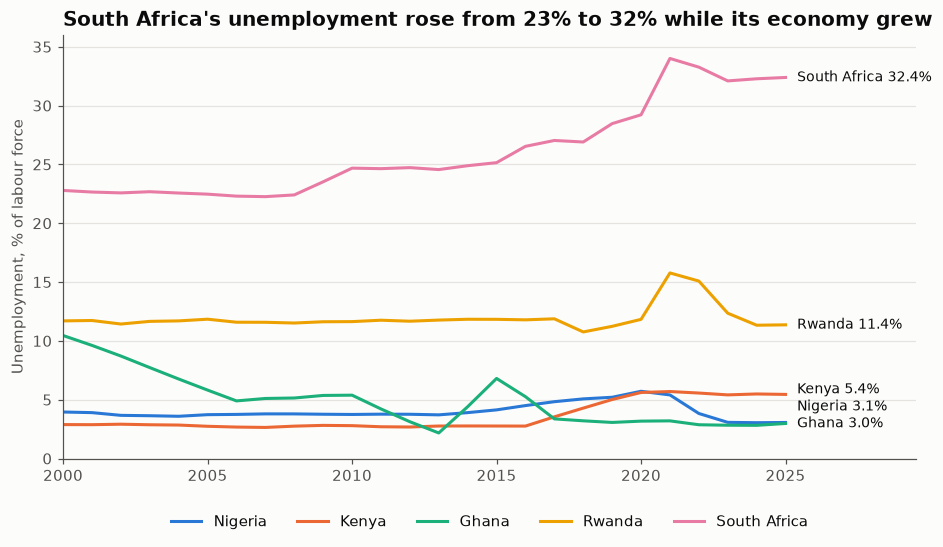

year,2000,2025,change_pp
country_iso3,,,
Nigeria,4.0,3.1,-0.9
Kenya,2.9,5.4,2.6
Ghana,10.5,3.0,-7.5
Rwanda,11.7,11.4,-0.3
South Africa,22.8,32.4,9.6


In [7]:
fig, ax = plt.subplots()
for c in COUNTRIES:
    d = country_year[country_year.country_iso3 == c]
    ax.plot(d.year, d.unemployment_pct, color=COLORS[c], label=NAMES[c])
label_line_ends(ax, country_year, "unemployment_pct", fmt="{:.1f}%")
ax.set_xlim(2000, 2029.5)
ax.set_ylim(0, 36)
ax.set_ylabel("Unemployment, % of labour force")
ax.set_title("South Africa's unemployment rose from 23% to 32% while its economy grew")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

change = country_year[country_year.year.isin([2000, 2025])].pivot(index="country_iso3", columns="year", values="unemployment_pct")
change["change_pp"] = change[2025] - change[2000]
change.reindex(COUNTRIES).rename(index=NAMES).round(1)

**What this shows:**
- **South Africa is the outlier:** unemployment climbed from 23% to 32%, with no year of real improvement. Its slow growth didn't create enough jobs.
- **Rwanda stayed flat at ~12%** despite the fastest growth (apart from a COVID spike to 16% in 2021).
- **Ghana is the one case where unemployment fell while the economy grew**: from 10.5% in 2000 to about 5% by 2006, and 3% today.
- **Nigeria and Kenya sit low (3–6%)**, and Kenya's roughly doubled after 2016.

**Big caveat: low unemployment ≠ good jobs.** In economies where most work is informal (street trading, small farms),
people can't afford to be "unemployed", so they take any work. Nigeria's 3% doesn't mean its labour market is healthier than South Africa's.
A better measure would be informal employment or working poverty, which we could add to the pipeline later.

**Answer to Q4:** apart from Ghana in the early 2000s, growth didn't bring unemployment down, and in South Africa it rose steadily.
But the unemployment rate is a weak measure of job quality in these economies.

## 5. Did access to mobile phones spread?

Mobile subscriptions per 100 people: a common measure of access to communication and mobile money.

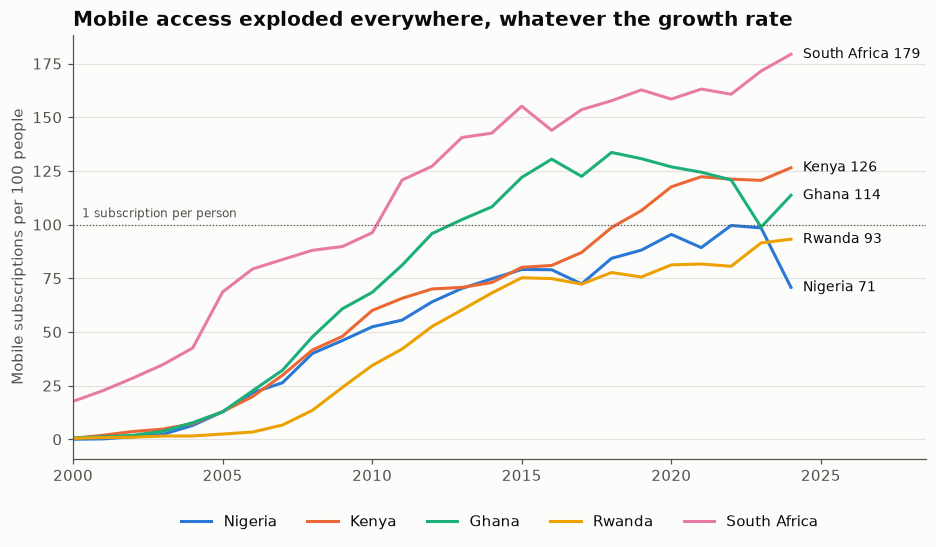

In [8]:
fig, ax = plt.subplots()
for c in COUNTRIES:
    d = country_year[country_year.country_iso3 == c]
    ax.plot(d.year, d.mobile_per_100, color=COLORS[c], label=NAMES[c])
label_line_ends(ax, country_year, "mobile_per_100")
ax.axhline(100, color=MUTED, linewidth=0.8, linestyle=":")
ax.text(2000.3, 102, "1 subscription per person", fontsize=8, color=MUTED, va="bottom")
ax.set_xlim(2000, 2028.5)
ax.set_ylabel("Mobile subscriptions per 100 people")
ax.set_title("Mobile access exploded everywhere, whatever the growth rate")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

**What this shows:** all five countries went from almost no mobile subscriptions in 2000 to **70–180 per 100 people by 2024**.
It spread **regardless of growth**: slow-growing South Africa leads (179), and fast-growing Rwanda is lowest (93).

**Watch-outs:**
- **Over 100 doesn't mean everyone has a phone.** It counts *subscriptions*, and many people have several SIM cards. It measures market size, not how many people are connected.
- **Sudden drops are usually rule changes, not people giving up phones.** Ghana dipped in 2023 (121 → 99) and **Nigeria dropped in 2024 (100 → 71)** . Both countries had campaigns around then to cut off SIM cards that weren't registered to a national ID. Check that before using the numbers.

**Answer to Q5:** yes, dramatically. This is the clearest "development" improvement in the data, and the one least tied to GDP growth.
This sets up **Project 3 (mobile money)**.

## 6. Putting it together: a scorecard per country

In [9]:
growth = country_year.groupby("country_iso3").gdp_growth_pct.mean()
unemp = country_year.set_index(["country_iso3", "year"]).unemployment_pct.unstack()
mobile = country_year.set_index(["country_iso3", "year"]).mobile_per_100.unstack()

scorecard = pd.DataFrame({
    "Avg GDP growth 2000–25, %": growth,
    "Poverty: first survey, %": first_last.first_pct,
    "Poverty: latest survey, %": first_last.last_pct,
    "Poverty change, pp": first_last.change_pp,
    "Unemployment change 2000–25, pp": unemp[2025] - unemp[2000],
    "Mobile per 100, 2024": mobile[2024],
}).reindex(COUNTRIES).rename(index=NAMES).round(1)

(scorecard.style.format("{:.1f}")
    .background_gradient(subset=["Poverty change, pp"], cmap="Blues_r")
    .set_caption("Development scorecard, sorted as in every chart above"))

,"Avg GDP growth 2000–25, %","Poverty: first survey, %","Poverty: latest survey, %","Poverty change, pp","Unemployment change 2000–25, pp","Mobile per 100, 2024"
country_iso3,,,,,,
Nigeria,4.8,51.1,41.8,-9.3,-0.9,70.8
Kenya,4.4,44.6,45.5,0.9,2.6,126.5
Ghana,5.6,60.9,39.0,-21.9,-7.5,113.6
Rwanda,7.5,82.3,38.6,-43.7,-0.3,93.2
South Africa,2.2,47.9,17.4,-30.5,9.6,179.3


**The answer to the main question:** **only partly.**

- **Growth and development moved together in Rwanda**: fastest growth, biggest fall in poverty. It's the clearest success story, although unemployment didn't improve.
- **South Africa improved without much growth**: poverty fell sharply, but unemployment rose by 10 points. Growth wasn't the driver.
- **Kenya grew steadily, but poverty is back where it was in 2005.** Growth didn't reach the poorest.
- **Nigeria shows the reverse:** when growth collapsed after 2015, poverty rose again.
- **Mobile access spread everywhere**, regardless of growth.

**In one sentence:** across these five countries, GDP growth **helped but didn't guarantee** better lives. Who benefits from growth mattered as much as how fast it was.

## 7. Limitations (say these before anyone asks)

1. **Poverty is sparse:** 3–6 surveys per country, at irregular intervals. Ghana's latest is 2016. Survey-to-survey changes can also reflect changes in survey methods.
2. **Unemployment is a modelled ILO estimate** and misses informal work, so it understates labour-market problems in Nigeria, Kenya and Ghana.
3. **Mobile counts subscriptions, not people,** and the sharp drops (Ghana 2023, Nigeria 2024) probably reflect SIM-registration rules, not real changes.
4. **Small sample:** 5 countries, 21 survey spans. Patterns, not proof.
5. **Correlation, not causation:** nothing here says growth *caused* anything. Other factors (social grants, oil prices, conflict, population growth) aren't in the data.
6. **GDP growth isn't per person.** With populations growing 2–3% a year, growth per person is much lower. Adding population (`SP.POP.TOTL`) to `config/indicators.yml` is the obvious next step.